# Credit Scoring Prediction using Machine Learning

**Author:** Afia Konadu  
**Project:** Credit Scoring Prediction  
**Date:** July/August 2026

---

## Project Overview

Credit scoring estimates the likelihood that an applicant will repay a loan or credit obligation. It helps financial institutions make consistent lending decisions, manage credit risk, and allocate credit responsibly.

This project develops and compares classification models that predict the `Risk` outcome in the German Credit dataset. The objective is to identify a reliable model for distinguishing lower- and higher-risk credit applicants while documenting the complete analytical workflow.

## 1. Import Libraries

The imports below are grouped by purpose: data handling, visualisation, preprocessing, modelling, evaluation, tuning, and model persistence. Keeping them together makes the notebook easier to review and reproduce.

In [2]:
# Data handling
from pathlib import Path
import os

import joblib
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

## 2. Load Dataset

The analysis uses the German Credit dataset, a commonly used credit-risk classification dataset based on customer demographic, financial, and loan-purpose information. The target variable is `Risk`, where the original labels represent `good` and `bad` credit risk. The next cells load the source file and report its dimensions without modifying it.

In [20]:
from pathlib import Path
import pandas as pd

# Dataset configuration
DATASET_FILENAME = "german_credit_data.csv"

DATASET_PATH = Path("../data") / DATASET_FILENAME

df = pd.read_csv(DATASET_PATH)

TARGET = "Risk"

print(f"Dataset loaded successfully from: {DATASET_PATH.resolve()}")


Dataset loaded successfully from: ../data/german_credit_data.csv


In [21]:
print(df.shape)


(1000, 11)


# 3. Exploratory Data Analysis

Exploratory data analysis describes the raw dataset before cleaning or modelling. The following subsections examine its structure, quality, distributions, and relationships with the target variable.

## Dataset Overview

This section reviews the dataset dimensions, representative records, column names, data types, memory footprint, and high-level summaries. The dataset contains 1,000 records and 11 columns before cleaning, including the `Risk` target.


In [22]:
print(f"Dataset shape (rows, columns): {df.shape}")

print("\nFirst 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("Data Type").to_frame())

memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nMemory usage: {memory_mb:.2f} MB")

print("\nNumerical summary statistics:")
display(df.describe())

categorical_columns = df.select_dtypes(include=["object", "category", "bool", "string"]).columns
if len(categorical_columns) > 0:
    print("Categorical summary statistics:")
    display(df[categorical_columns].describe())
else:
    print("No categorical columns were detected.")

Dataset shape (rows, columns): (1000, 11)


Column names:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

Data types:


,Data Type
Unnamed: 0,int64
Age,int64
Sex,str
Job,int64
Housing,str
Saving accounts,str
Checking account,str
Credit amount,int64
Duration,int64
Purpose,str



Memory usage: 0.11 MB

Numerical summary statistics:


,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


Categorical summary statistics:


,Sex,Housing,Saving accounts,Checking account,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


## Missing Values

Missing-value checks identify fields that require treatment before modelling. The next cell reports both the number and percentage of missing values in each raw column.

## Duplicate Rows

Duplicate-row checks identify repeated observations that could unintentionally influence model training. This is a diagnostic check only; the original workflow does not remove any rows.


In [23]:
missing_values = df.isna().sum()
missing_percentage = (missing_values / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
}).sort_values("Missing Values", ascending=False)

print("Missing values by column:")
display(missing_summary)

duplicate_rows = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_rows}")

Missing values by column:


,Missing Values,Missing Percentage
Checking account,394,39.4
Saving accounts,183,18.3
Unnamed: 0,0,0.0
Sex,0,0.0
Age,0,0.0
Housing,0,0.0
Job,0,0.0
Credit amount,0,0.0
Duration,0,0.0
Purpose,0,0.0


Duplicate rows: 0


## Target Distribution

The target variable is checked directly to confirm that `Risk` is available and to understand the balance between its classes. Class balance is important when interpreting classification metrics later in the notebook.

Target column identified: Risk

Class counts:


,Count
Risk,
good,700
bad,300


Class percentages:


,Percentage
Risk,
good,70.0
bad,30.0


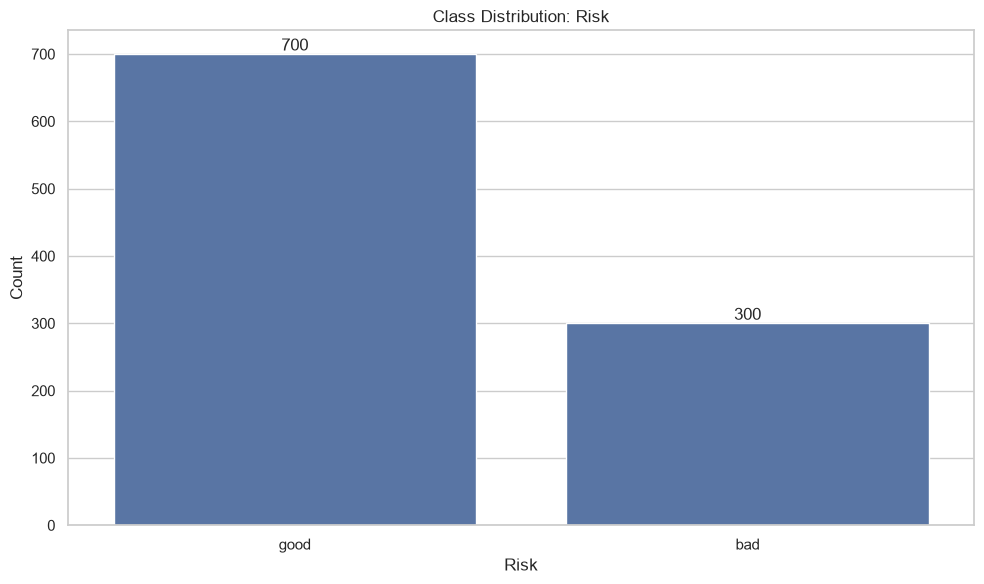

In [24]:
target_candidates = ["CreditRisk", "Risk", "Default", "Class", "target"]
target_column = next((column for column in target_candidates if column in df.columns), None)

if target_column is not None:
    print(f"Target column identified: {target_column}")
    class_counts = df[target_column].value_counts(dropna=False)
    class_percentages = (df[target_column].value_counts(dropna=False, normalize=True) * 100).round(2)

    print("\nClass counts:")
    display(class_counts.rename("Count").to_frame())

    print("Class percentages:")
    display(class_percentages.rename("Percentage").to_frame())

    ax = sns.countplot(data=df, x=target_column, order=class_counts.index)
    ax.set_title(f"Class Distribution: {target_column}")
    ax.set_xlabel(target_column)
    ax.set_ylabel("Count")
    for container in ax.containers:
        ax.bar_label(container)
    plt.tight_layout()
    plt.show()
else:
    print("No target column was found. Please manually specify the target column before continuing.")

## Numerical Summary

Numerical summary statistics describe the central tendency, spread, and range of measurable applicant and loan characteristics. They are displayed in the dataset overview before distribution plots are created.


## Numerical Visualizations

Histograms and KDE curves show the distribution of each numerical feature. They help reveal skewness, multiple peaks, and unusually extreme observations.

Numerical columns (5): ['Unnamed: 0', 'Age', 'Job', 'Credit amount', 'Duration']


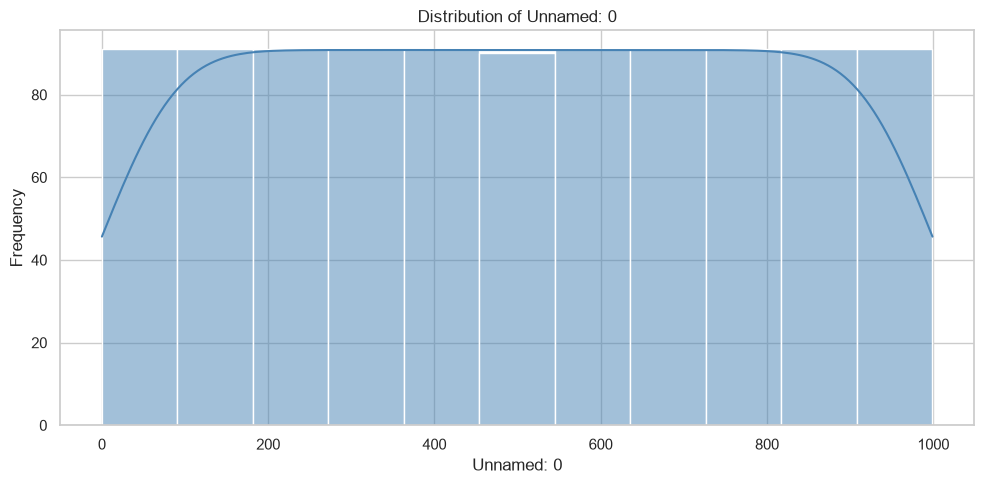

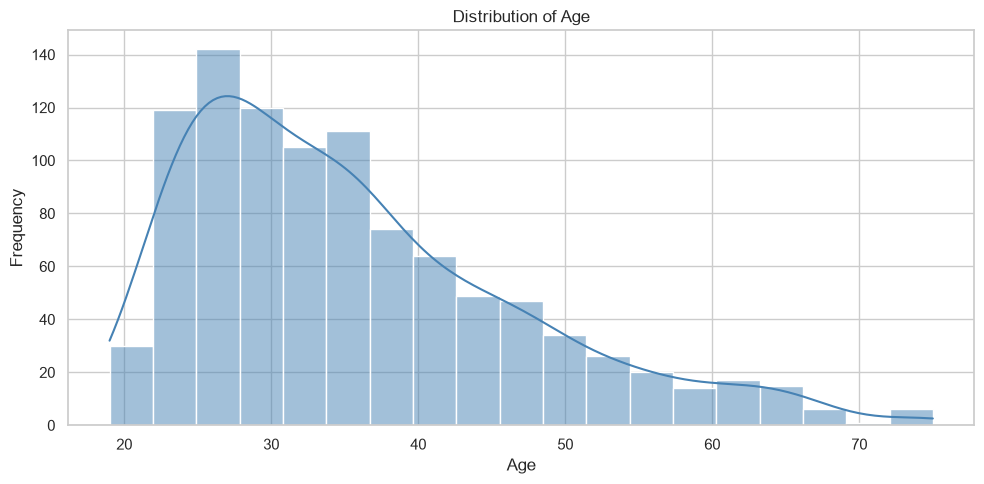

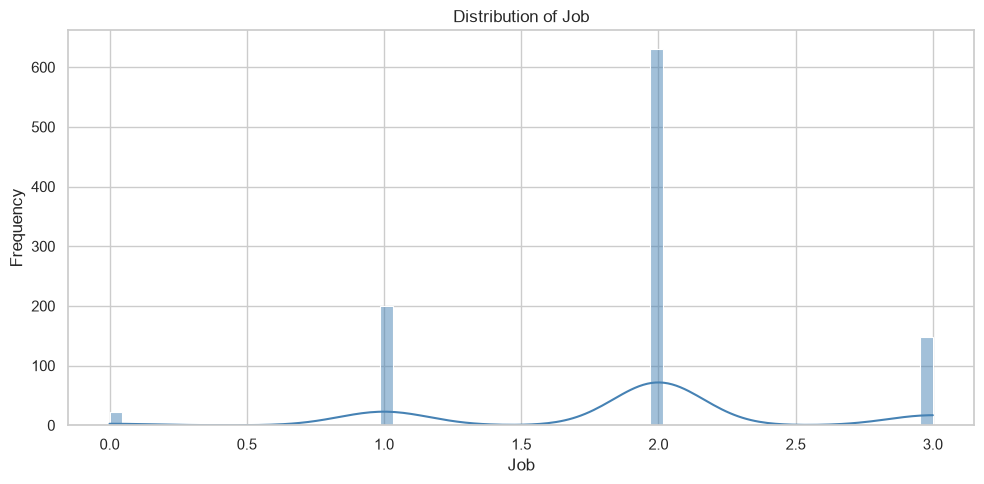

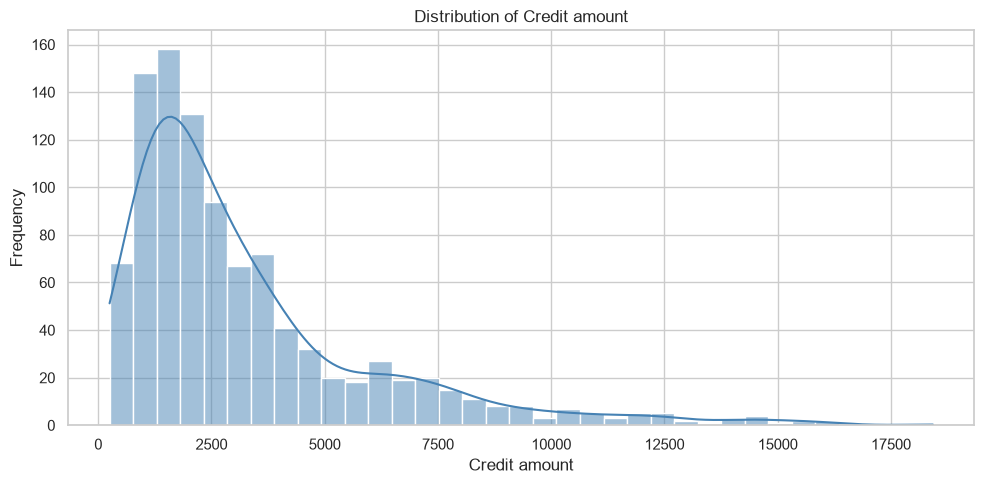

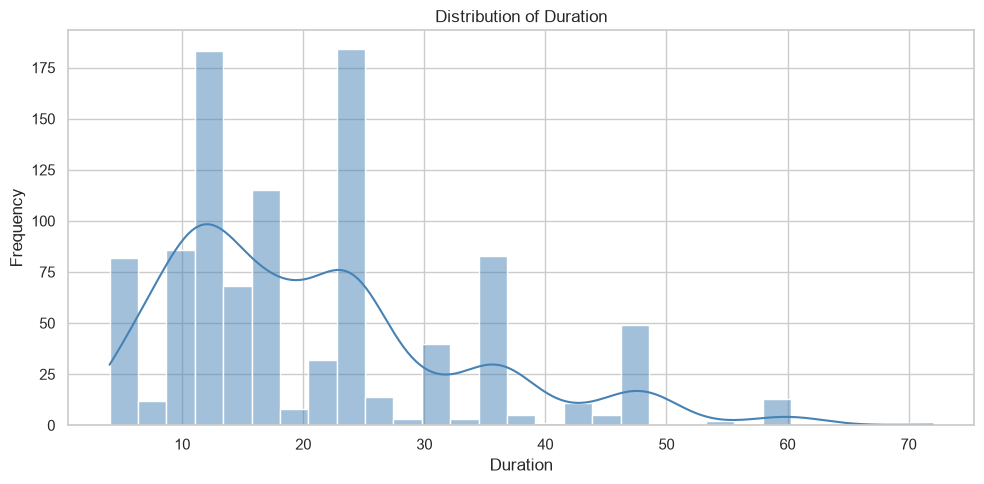

In [25]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
print(f"Numerical columns ({len(numerical_columns)}): {numerical_columns}")

# Draw one histogram and KDE curve for every numerical feature.
for column in numerical_columns:
    fig, ax = plt.subplots(figsize=(10,5))
    sns.histplot(data=df, x=column, kde=True, bins="auto", color="steelblue")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

if not numerical_columns:
    print("No numerical columns were detected.")

## Categorical Summary

Categorical summaries show the frequency and coverage of the non-numeric applicant and loan attributes. The visualisations below use count plots to make these distributions easy to compare.

## Categorical Visualizations

Each count plot displays the most frequent categories for one categorical feature. Missing values are labelled only for visualisation, leaving the raw dataset unchanged at this stage.


Categorical columns (6): ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose', 'Risk']


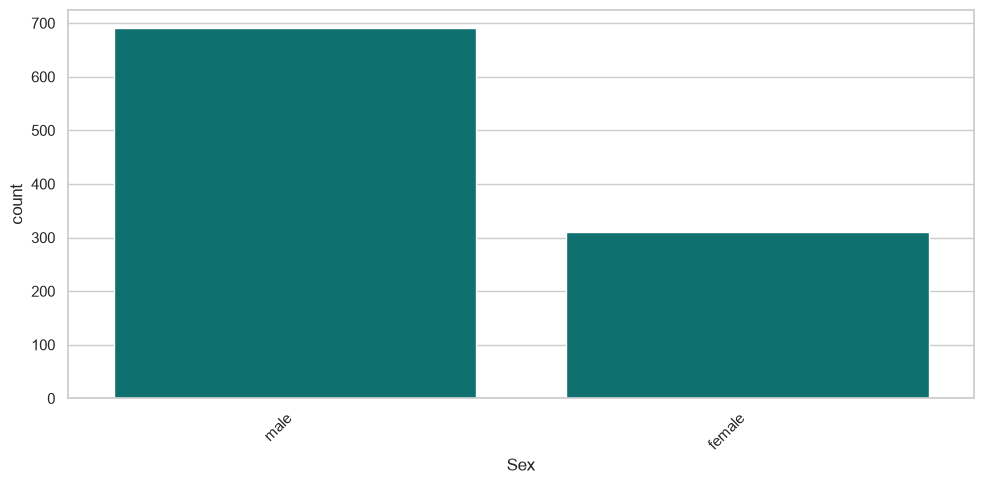

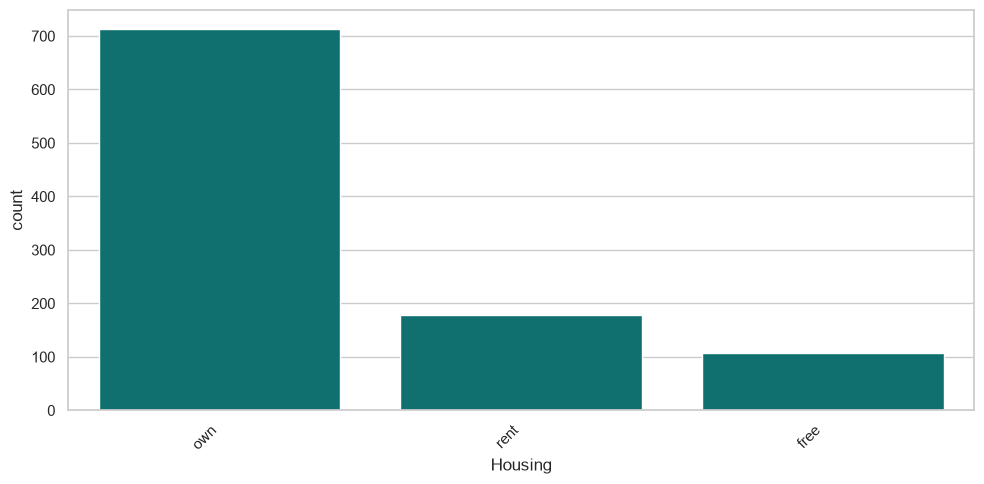

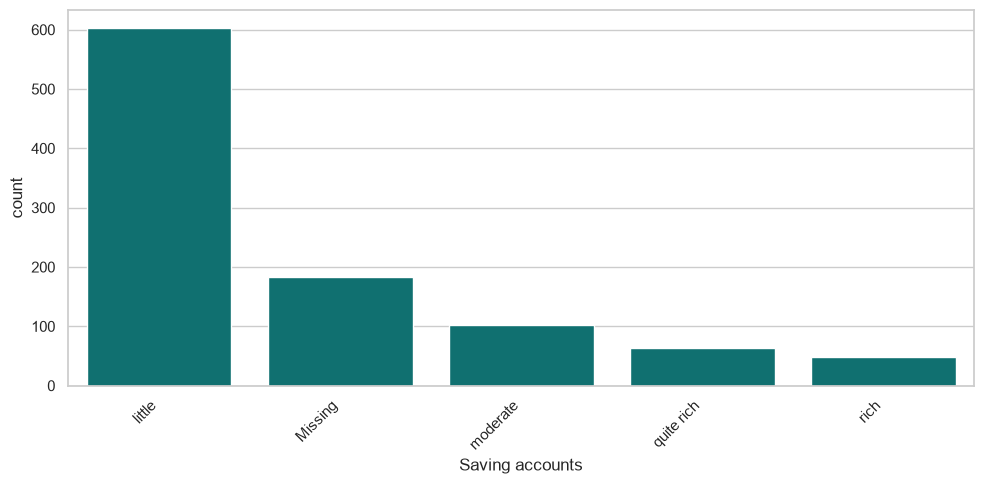

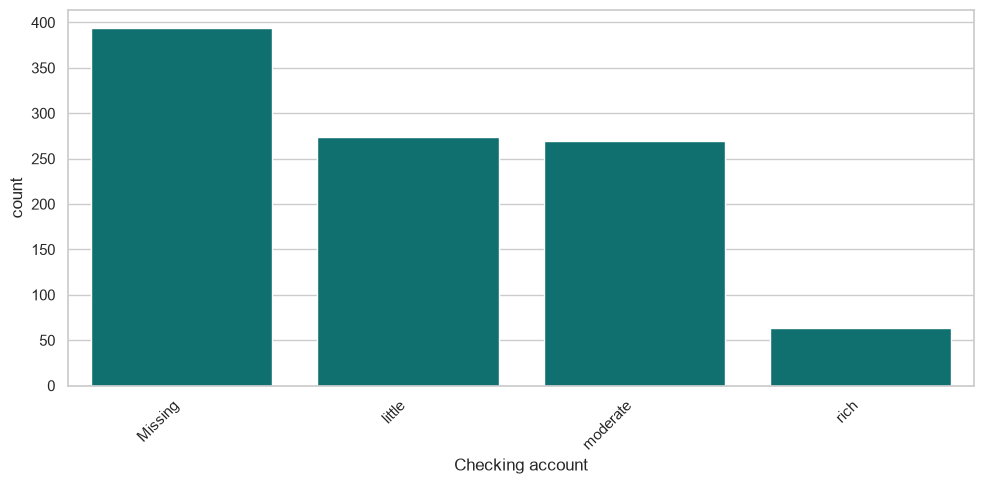

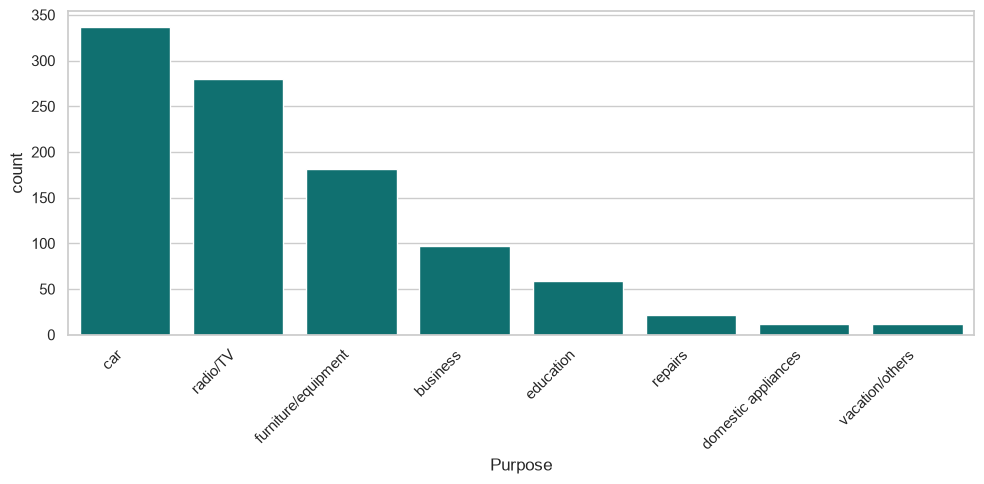

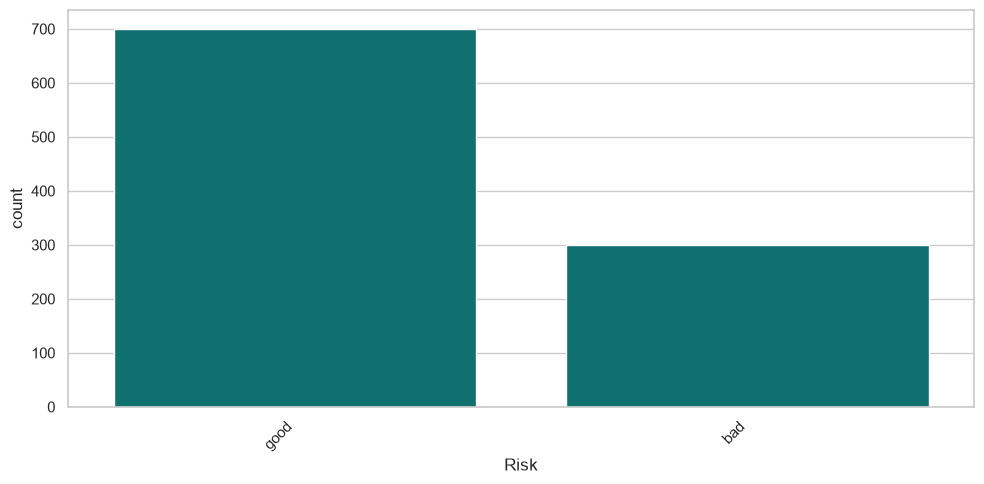

In [26]:
categorical_columns = df.select_dtypes(include=["object", "string","category", "bool"]).columns.tolist()
print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")

# Rotate labels to keep category names readable.
for column in categorical_columns:

    plot_df = df.copy()

    plot_df[column] = plot_df[column].fillna("Missing")

    top_categories = (
        plot_df[column]
        .value_counts()
        .head(10)
        .index
    )

    plot_data = plot_df[plot_df[column].isin(top_categories)]

    fig, ax = plt.subplots(figsize=(10,5))

    sns.countplot(
        data=plot_data,
        x=column,
        order=top_categories,
        color="teal",
        ax=ax
    )

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

if not categorical_columns:
    print("No categorical columns were detected.")

## Target Distribution

The `Risk` target is examined by count and percentage. Since the dataset contains more `good` than `bad` records, later evaluation considers several metrics rather than accuracy alone.


Risk distribution:


,Count
Risk,
good,700
bad,300


Risk percentages:


,Percentage
Risk,
good,70.0
bad,30.0


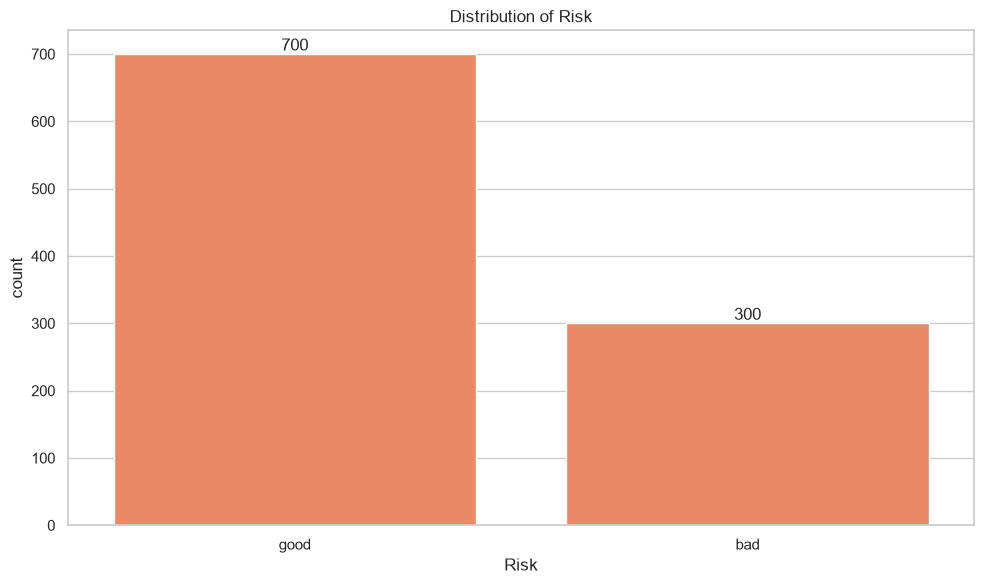

Class balance: the largest class represents 70.00% of records, so the classes are uneven.


In [27]:
if "Risk" in df.columns:
    risk_counts = df["Risk"].value_counts(dropna=False)
    risk_percentages = (df["Risk"].value_counts(dropna=False, normalize=True) * 100).round(2)

    print("Risk distribution:")
    display(risk_counts.rename("Count").to_frame())
    print("Risk percentages:")
    display(risk_percentages.rename("Percentage").to_frame())

    ax = sns.countplot(data=df, x="Risk", order=risk_counts.index, color="coral")
    ax.set_title("Distribution of Risk")
    for container in ax.containers:
        ax.bar_label(container)
    plt.tight_layout()
    plt.show()

    largest_class_share = risk_percentages.max()
    if largest_class_share > 60:
        print(f"Class balance: the largest class represents {largest_class_share:.2f}% of records, so the classes are uneven.")
    else:
        print(f"Class balance: the largest class represents {largest_class_share:.2f}% of records, so the classes appear relatively balanced.")
else:
    print("A column named 'Risk' was not found, so Risk-specific target analysis was skipped.")

## Numerical Visualizations by Target

Boxplots compare the distribution of each numerical feature between `Risk` classes. They help identify differences in central tendency, spread, and potential outliers without changing the data.


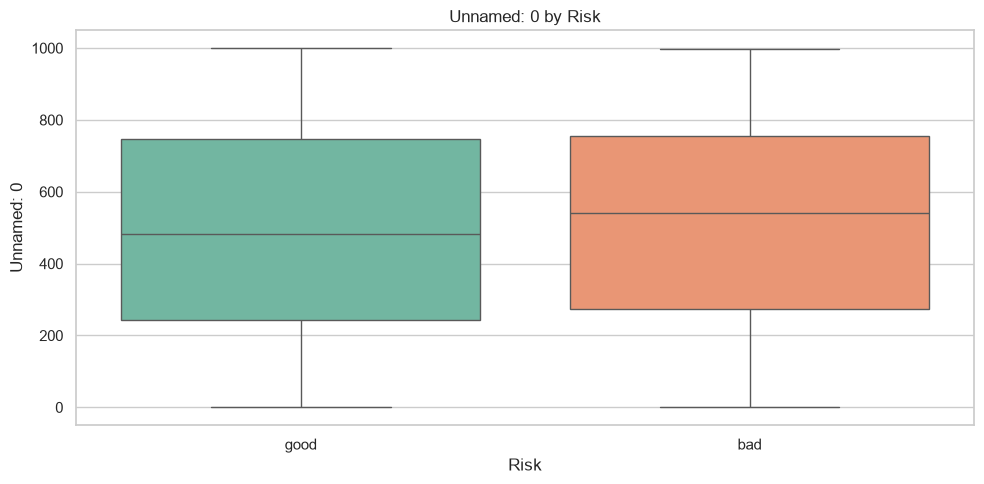

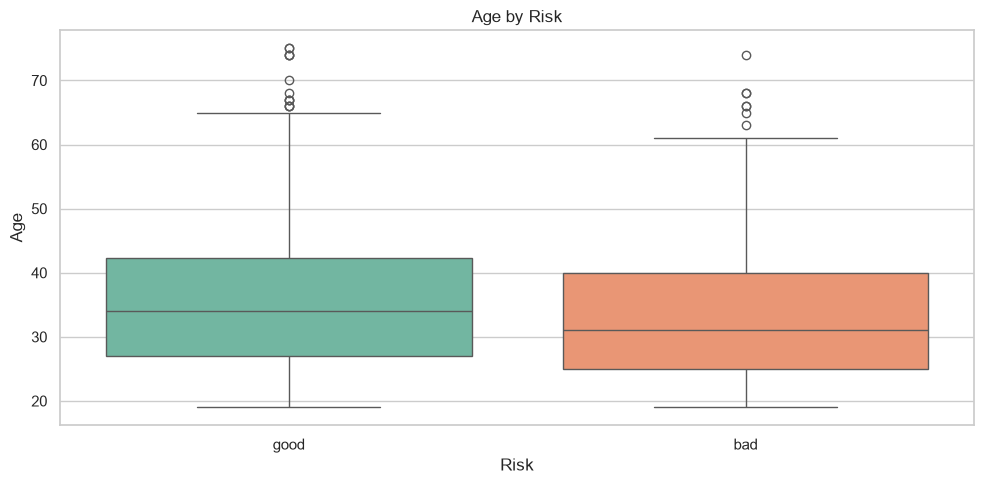

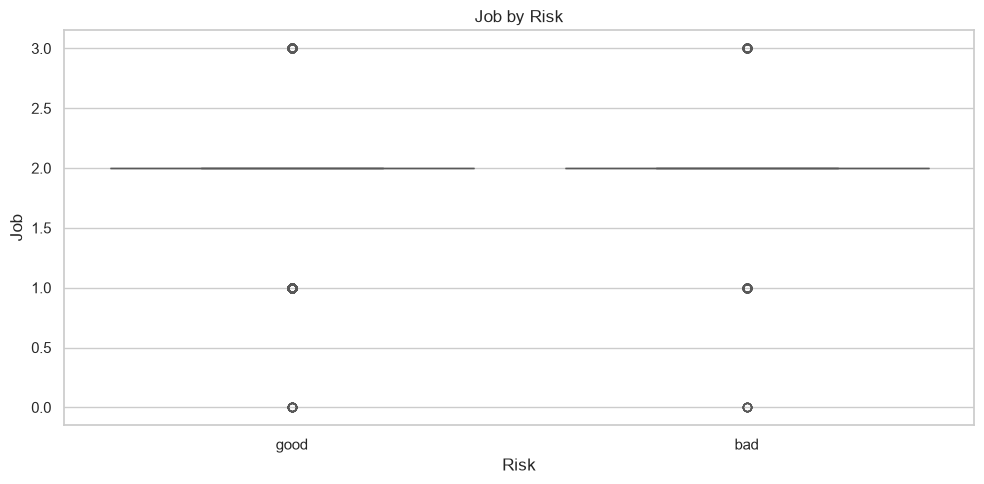

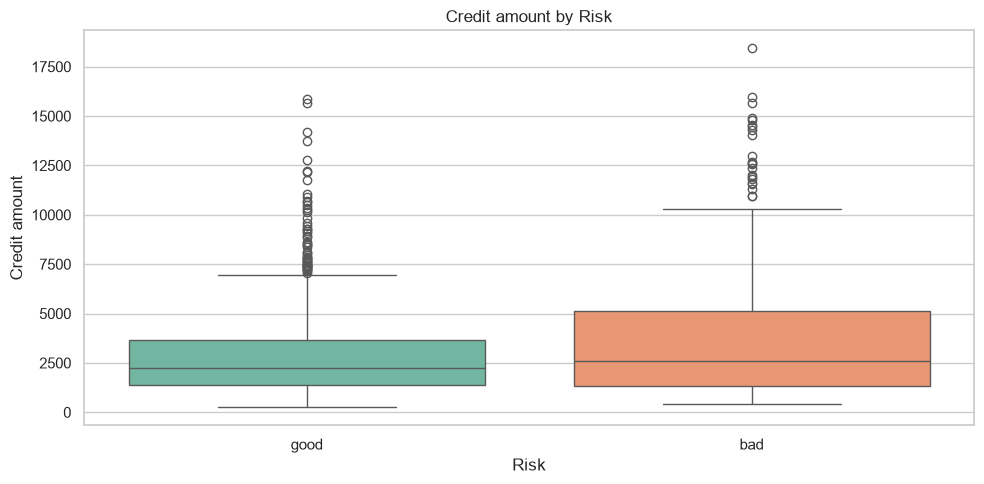

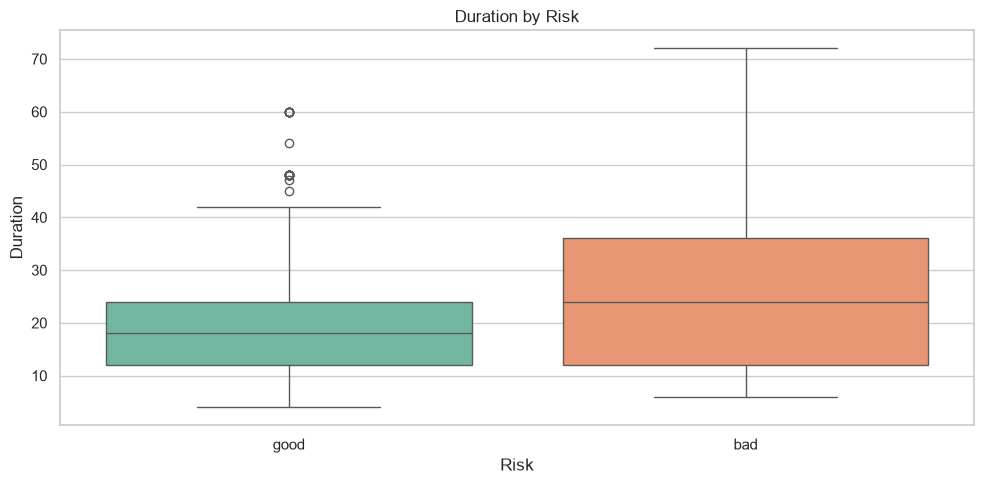

In [10]:
if "Risk" in df.columns:
    for column in numerical_columns:
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=df, x="Risk", y=column, hue="Risk", legend=False, palette="Set2")
        plt.title(f"{column} by Risk")
        plt.xlabel("Risk")
        plt.ylabel(column)
        plt.tight_layout()
        plt.show()
else:
    print("A column named 'Risk' was not found, so numerical comparisons were skipped.")

In [29]:
df.isnull().sum()


Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

## Categorical Visualizations by Target

Grouped count plots compare category frequencies across `Risk` classes. These charts provide descriptive context for possible relationships between categorical attributes and credit risk.


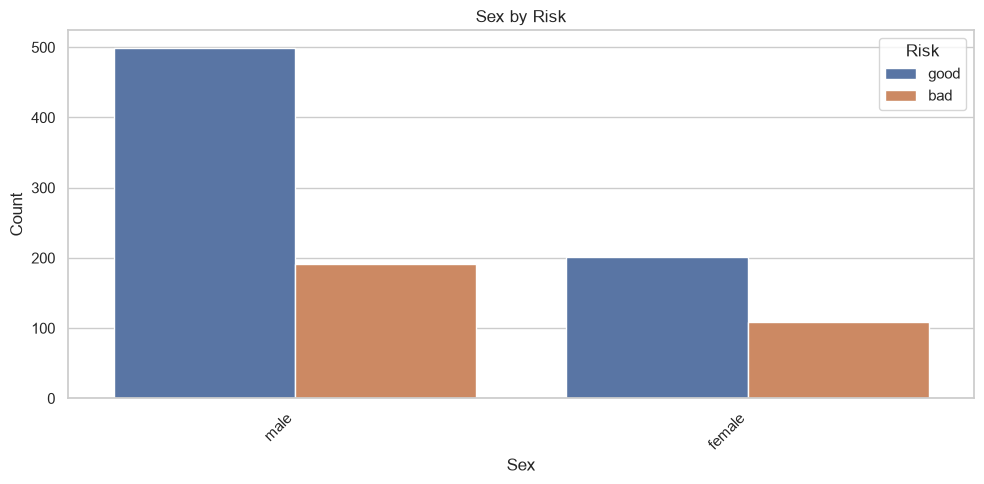

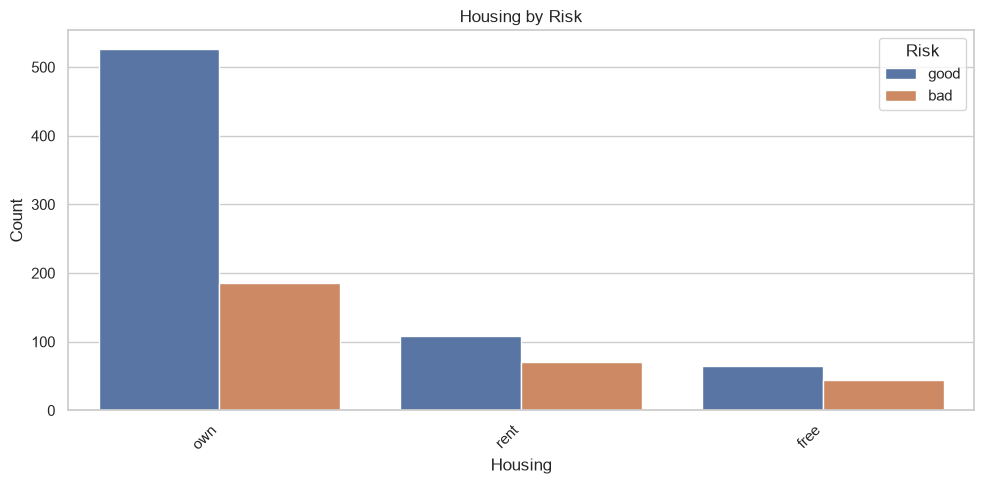

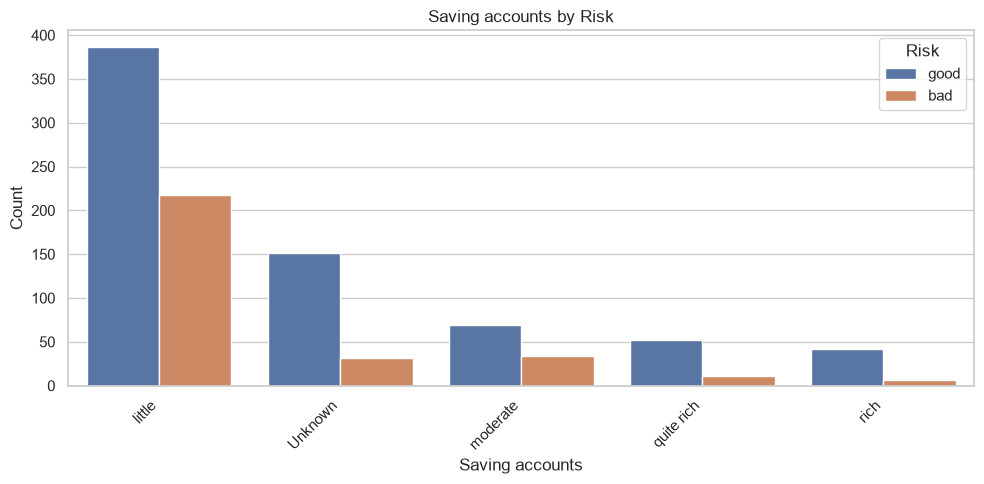

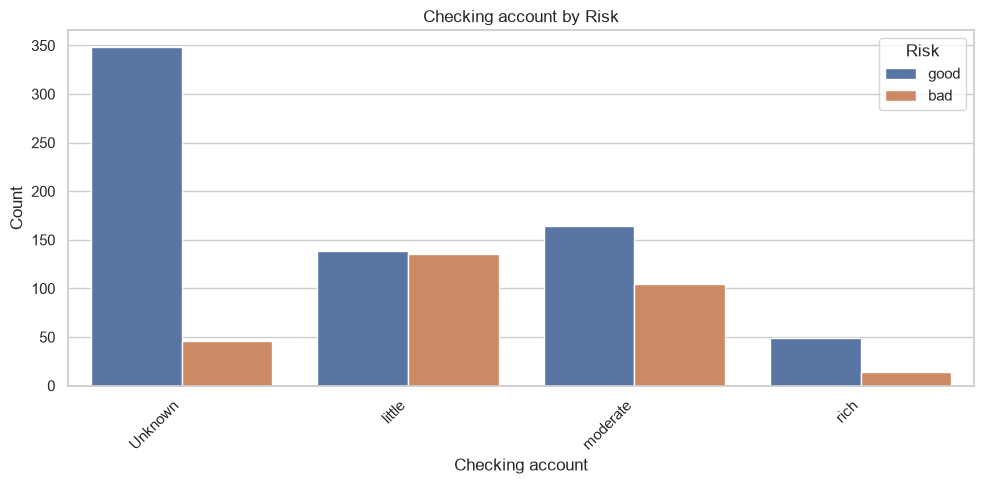

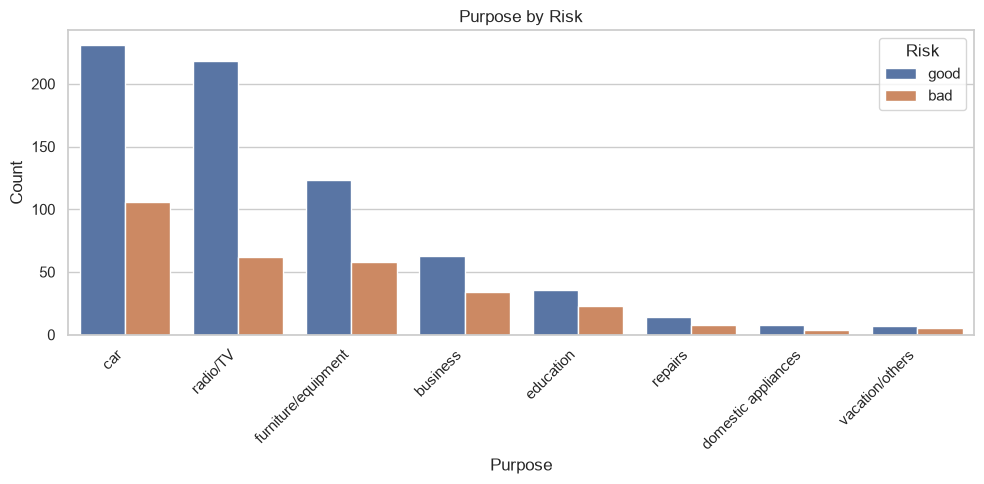

In [33]:
if "Risk" in df.columns:
    feature_columns = [column for column in categorical_columns if column != "Risk"]
    for column in feature_columns:
        plt.figure(figsize=(10, 5))
        sns.countplot(data=df, x=column, hue="Risk", order=df[column].value_counts(dropna=False).index)
        plt.title(f"{column} by Risk")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.legend(title="Risk")
        plt.tight_layout()
        plt.show()
else:
    print("A column named 'Risk' was not found, so categorical comparisons were skipped.")

## Correlation Analysis

Correlation measures the strength and direction of linear relationships between numerical features. Values near 1 or -1 indicate stronger positive or negative relationships; correlation does not imply causation.


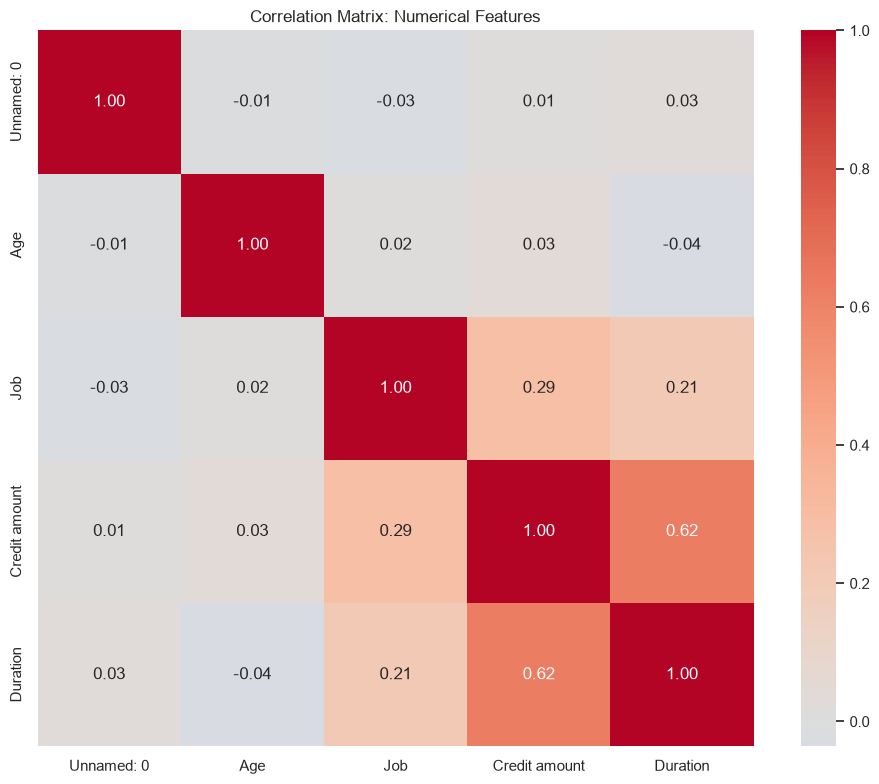

In [31]:
if len(numerical_columns) >= 2:
    correlation_matrix = df[numerical_columns].corr()
    plt.figure(figsize=(max(10, len(numerical_columns)), max(8, len(numerical_columns) * 0.7)))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
    plt.title("Correlation Matrix: Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required to create a correlation matrix.")

# 4. Data Cleaning

Data cleaning prepares the dataset without altering the established analytical design. The unnecessary exported index column (`Unnamed: 0`) is removed. Missing values in `Saving accounts` and `Checking account` are assigned the explicit category `Unknown`, preserving the fact that the information was unavailable. Duplicate and outlier checks are documented below; no duplicate removal or outlier treatment is applied.


In [34]:
df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
print(df.shape)
categorical_missing = [
    "Saving accounts",
    "Checking account"
]

for column in categorical_missing:
    df[column] = df[column].fillna("Unknown")
    
print(df.isnull().sum())

(1000, 10)
Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64


## Duplicate and Outlier Review

No duplicate records were found in the dataset. Boxplots are used to inspect `Age`, `Credit amount`, and `Duration` for potential outliers. Observations outside the interquartile range remain because they are plausible customer records rather than confirmed data-entry errors.


Duplicate rows: 0


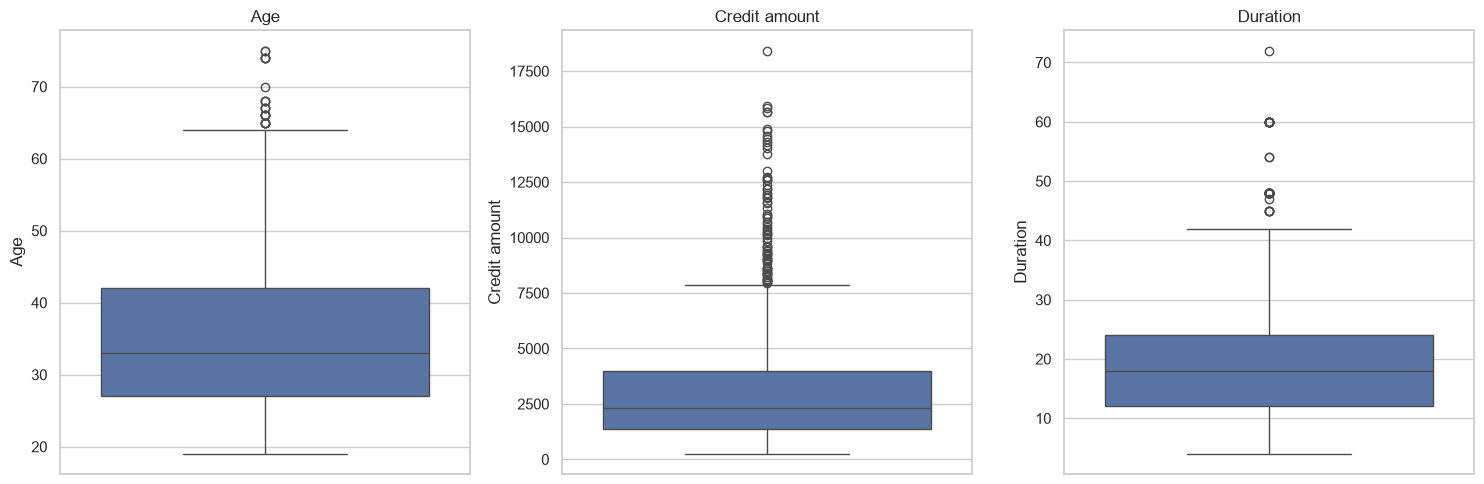

In [16]:
## check duplicates
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

##summary statistics
numerical_columns = [
    "Age",
    "Credit amount",
    "Duration"
]
df[numerical_columns].describe().T

## visualize outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(
        data=df,
        y=column,
        ax=ax
    )
    ax.set_title(column)

plt.tight_layout()
plt.show()


# 5. Feature Engineering

Feature engineering converts the cleaned dataset into a model-ready representation while preserving its information.

## Encoding Review

The following check confirms the observed categories before encoding. This makes the subsequent label and one-hot encoding steps transparent and reproducible.


In [35]:
for column in [
    "Sex",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Purpose"
]:
    print(f"\n{column}")
    print(sorted(df[column].unique()))


Sex
['female', 'male']

Housing
['free', 'own', 'rent']

Saving accounts
['Unknown', 'little', 'moderate', 'quite rich', 'rich']

Checking account
['Unknown', 'little', 'moderate', 'rich']

Purpose
['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']


In [36]:
print(df["Sex"].unique())
print(df["Risk"].unique())

print(repr(df["Sex"].iloc[0]))
print(repr(df["Risk"].iloc[0]))


<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str
<ArrowStringArray>
['good', 'bad']
Length: 2, dtype: str
'male'
'good'


In [37]:
##Encode the target variable
df["Risk"] = df["Risk"].map({
    "good": 1,
    "bad": 0
})
print(df["Risk"].value_counts())

## Encode sex
df["Sex"] = df["Sex"].map({
    "male": 1,
    "female": 0
})
print(df["Sex"].value_counts())

## Encode the ordinal features
# For Saving accounts:
saving_mapping = {
    "Unknown": 0,
    "little": 1,
    "moderate": 2,
    "quite rich": 3,
    "rich": 4
}

df["Saving accounts"] = df["Saving accounts"].map(saving_mapping)

# For Checking account:
checking_mapping = {
    "Unknown": 0,
    "little": 1,
    "moderate": 2,
    "rich": 3
}

df["Checking account"] = df["Checking account"].map(checking_mapping)

print(df.head())

print("\nData types:\n")
print(df.dtypes)

Risk
1    700
0    300
Name: count, dtype: int64
Sex
1    690
0    310
Name: count, dtype: int64

Data types:

Age                 int64
Sex                 int64
Job                 int64
Housing               str
Saving accounts     int64
Checking account    int64
Credit amount       int64
Duration            int64
Purpose               str
Risk                int64
dtype: object


In [38]:
## for housing and purpose

df = pd.get_dummies(
    df,
    columns=["Housing", "Purpose"],
    drop_first=True,
    dtype=int
)
print(df.head())

print("\nShape:", df.shape)

print("\nData types:")
print(df.dtypes)

Shape: (1000, 17)

Data types:
Age                            int64
Sex                            int64
Job                            int64
Saving accounts                int64
Checking account               int64
Credit amount                  int64
Duration                       int64
Risk                           int64
Housing_own                    int64
Housing_rent                   int64
Purpose_car                    int64
Purpose_domestic appliances    int64
Purpose_education              int64
Purpose_furniture/equipment    int64
Purpose_radio/TV               int64
Purpose_repairs                int64
Purpose_vacation/others        int64
dtype: object


# 6. Train/Test Split

The features are separated from the `Risk` target and split into 80% training data and 20% test data. `stratify=y` preserves the target-class proportions in both sets, while `random_state=42` makes the split reproducible.


In [39]:
# Separate features and target
X = df.drop("Risk", axis=1)
y = df["Risk"]

# Create the reproducible, stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify the split
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())


X_train: (800, 16)
X_test : (200, 16)

y_train:
Risk
1    560
0    240
Name: count, dtype: int64

y_test:
Risk
1    140
0     60
Name: count, dtype: int64


## Feature Scaling

Standard scaling is applied to the training features and then reused to transform the test features. Scaling is required for Logistic Regression because feature magnitudes can affect its optimisation; tree-based models continue to use the original unscaled features.


In [40]:
# Fit scaling only on the training data, then transform the test data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify
print(type(X_train_scaled))
print(type(X_test_scaled))

print(X_train_scaled.shape)
print(X_test_scaled.shape)


<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(800, 16)
(200, 16)


# 7. Logistic Regression

## Objective

Logistic Regression provides an interpretable linear baseline for predicting the probability of `good` credit risk.

## Model Training and Predictions

The model is trained on the scaled training features using the original configuration. Predictions for the held-out test set are shown below.


In [41]:
## create model
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

## train the model
log_model.fit(X_train_scaled, y_train)

## make prediction
y_pred = log_model.predict(X_test_scaled)

## preview the predictions
print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)


First 10 predictions:
[1 0 1 1 0 1 1 1 1 1]

First 10 actual values:
[1 1 1 1 0 1 1 0 0 1]


## Evaluation

Accuracy, precision, recall, F1-score, ROC-AUC, a confusion matrix, and a classification report evaluate the Logistic Regression model on the unchanged test set.


In [42]:
## calculate the metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)

## print them neatly
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

## confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

## classification report
print(classification_report(y_test, y_pred))

Accuracy : 0.6750
Precision: 0.7273
Recall   : 0.8571
F1-score : 0.7869
ROC-AUC  : 0.6602
[[ 15  45]
 [ 20 120]]
              precision    recall  f1-score   support

           0       0.43      0.25      0.32        60
           1       0.73      0.86      0.79       140

    accuracy                           0.68       200
   macro avg       0.58      0.55      0.55       200
weighted avg       0.64      0.68      0.65       200



## Interpretation

The baseline Logistic Regression achieves strong recall for the `good` class but lower performance for the `bad` class. Its ROC-AUC of 0.6602 establishes a useful linear benchmark, while leaving room for non-linear models to improve discrimination.


# 8. Decision Tree

## Objective

A Decision Tree models non-linear decision rules and interactions between applicant characteristics.

## Model Training and Predictions

The tree is trained on the original unscaled training features using the existing reproducible configuration. The next cell displays its test-set predictions.


In [43]:
## model creation
tree_model = DecisionTreeClassifier(
    random_state=42
)

## model training(unscaled data)
tree_model.fit(X_train, y_train)

## make prediction
tree_pred = tree_model.predict(X_test)

## preview the predictions
print("First 10 predictions:")
print(tree_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
[1 0 1 1 0 0 1 1 1 1]

First 10 actual values:
[1 1 1 1 0 1 1 0 0 1]


In [44]:
## make probability predictions
tree_prob = tree_model.predict_proba(X_test)[:, 1]

## calculate the metrics
tree_accuracy = accuracy_score(y_test, tree_pred)
tree_precision = precision_score(y_test, tree_pred)
tree_recall = recall_score(y_test, tree_pred)
tree_f1 = f1_score(y_test, tree_pred)
tree_auc = roc_auc_score(y_test, tree_prob)

## print the metrics
print(f"Accuracy : {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall   : {tree_recall:.4f}")
print(f"F1-score : {tree_f1:.4f}")
print(f"ROC-AUC  : {tree_auc:.4f}")

## confusion metrics
tree_cm = confusion_matrix(y_test, tree_pred)
print(tree_cm)

## classification report
print(classification_report(y_test, tree_pred))

Accuracy : 0.6600
Precision: 0.7535
Recall   : 0.7643
F1-score : 0.7589
ROC-AUC  : 0.5905
[[ 25  35]
 [ 33 107]]
              precision    recall  f1-score   support

           0       0.43      0.42      0.42        60
           1       0.75      0.76      0.76       140

    accuracy                           0.66       200
   macro avg       0.59      0.59      0.59       200
weighted avg       0.66      0.66      0.66       200



## Evaluation and Interpretation

The Decision Tree is evaluated with the same metrics and test set as Logistic Regression. Its ROC-AUC of 0.5905 and accuracy of 0.6600 are lower than the linear baseline, indicating that this single tree does not generalise as effectively for this split.


# 9. Random Forest

## Objective

Random Forest combines many decision trees to reduce the instability of a single tree and capture non-linear patterns in credit-risk features.

## Model Training and Predictions

The baseline forest is trained on the original unscaled training features with the established 100-estimator configuration. Its predictions are evaluated on the same held-out test set.


In [45]:
## Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

## train model
rf_model.fit(X_train, y_train)

## Make prediction
rf_pred = rf_model.predict(X_test)

## Test
print("First 10 predictions:")
print(rf_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
[1 1 1 1 1 1 1 1 0 1]

First 10 actual values:
[1 1 1 1 0 1 1 0 0 1]


In [46]:
## Probability prediction
rf_prob = rf_model.predict_proba(X_test)[:, 1]

## calculating metric
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

## print metrics
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")

## confusion matrix
rf_cm = confusion_matrix(y_test, rf_pred)
print(rf_cm)

## classification report
print(classification_report(y_test, rf_pred))

Accuracy : 0.7550
Precision: 0.7898
Recall   : 0.8857
F1-score : 0.8350
ROC-AUC  : 0.7407
[[ 27  33]
 [ 16 124]]
              precision    recall  f1-score   support

           0       0.63      0.45      0.52        60
           1       0.79      0.89      0.84       140

    accuracy                           0.76       200
   macro avg       0.71      0.67      0.68       200
weighted avg       0.74      0.76      0.74       200



## Evaluation and Interpretation

The baseline Random Forest records the strongest test-set performance: 0.7550 accuracy, 0.8350 F1-score, and 0.7407 ROC-AUC. It also achieves the highest recall for the `good` class, making it the leading baseline candidate.


# 10. Hyperparameter Tuning

GridSearchCV evaluates the existing Random Forest parameter grid using 5-fold cross-validation and accuracy as the scoring metric. Cross-validation estimates training-set performance across multiple folds, while the held-out test set remains reserved for final comparison. The best parameters and cross-validation score are retained exactly as in the original experiment.


In [47]:
## Parameter grid
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

## GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

## Grid search
grid_search.fit(X_train, y_train)

## Display best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(f"{grid_search.best_score_:.4f}")


Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation Accuracy:
0.7450


In [48]:
## Estimator
best_rf = grid_search.best_estimator_

## Prediction
best_pred = best_rf.predict(X_test)
best_prob = best_rf.predict_proba(X_test)[:, 1]

## Other Evaluations
best_accuracy = accuracy_score(y_test, best_pred)
best_precision = precision_score(y_test, best_pred)
best_recall = recall_score(y_test, best_pred)
best_f1 = f1_score(y_test, best_pred)
best_auc = roc_auc_score(y_test, best_prob)

## Print
print(f"Accuracy : {best_accuracy:.4f}")
print(f"Precision: {best_precision:.4f}")
print(f"Recall   : {best_recall:.4f}")
print(f"F1-score : {best_f1:.4f}")
print(f"ROC-AUC  : {best_auc:.4f}")

print(confusion_matrix(y_test, best_pred))

print(classification_report(y_test, best_pred))

Accuracy : 0.7400
Precision: 0.7750
Recall   : 0.8857
F1-score : 0.8267
ROC-AUC  : 0.7344
[[ 24  36]
 [ 16 124]]
              precision    recall  f1-score   support

           0       0.60      0.40      0.48        60
           1       0.78      0.89      0.83       140

    accuracy                           0.74       200
   macro avg       0.69      0.64      0.65       200
weighted avg       0.72      0.74      0.72       200



## Best Parameters and Interpretation

GridSearchCV identifies the displayed parameter combination with a best cross-validation accuracy of 0.7450. On the held-out test set, however, the tuned model's accuracy (0.7400) and ROC-AUC (0.7344) are slightly below the baseline Random Forest. For that reason, the tuned model is retained as an experiment but is not selected as the final model.


# 11. Feature Importance

Feature importance measures how much each input contributes to reducing impurity across the Random Forest's trees. Higher values indicate a greater relative contribution to the model's decisions; they do not establish causality.


                        Feature  Importance
5                 Credit amount    0.241276
0                           Age    0.177603
6                      Duration    0.161282
4              Checking account    0.128731
3               Saving accounts    0.066329
2                           Job    0.054232
1                           Sex    0.030329
9                   Purpose_car    0.027591
13             Purpose_radio/TV    0.023510
7                   Housing_own    0.022578
12  Purpose_furniture/equipment    0.021582
8                  Housing_rent    0.015368
11            Purpose_education    0.014396
14              Purpose_repairs    0.008406
15      Purpose_vacation/others    0.004258
10  Purpose_domestic appliances    0.002529


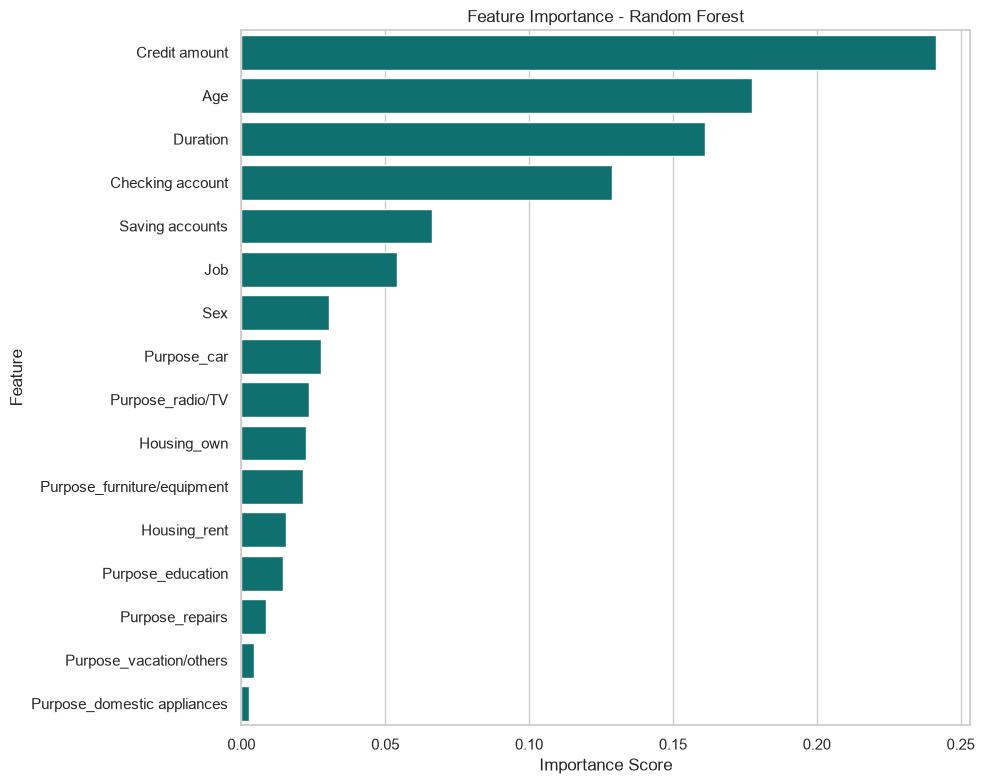

In [49]:
## Extraction
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

## Sorting
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

## Table
print(feature_importance)

## Plot results
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Interpretation

The feature-importance chart ranks `Credit amount`, `Age`, and `Duration` among the most influential variables in the baseline Random Forest. These scores describe the model's internal use of features, not the causal effect of a feature on an applicant's creditworthiness.


# 12. ROC Curve Comparison

The Receiver Operating Characteristic (ROC) curve plots true-positive rate against false-positive rate over all classification thresholds. Area Under the Curve (AUC) summarises discrimination ability: 0.5 is equivalent to random guessing and values closer to 1.0 indicate stronger separation of the classes. The graph compares all three baseline models on the same test set.


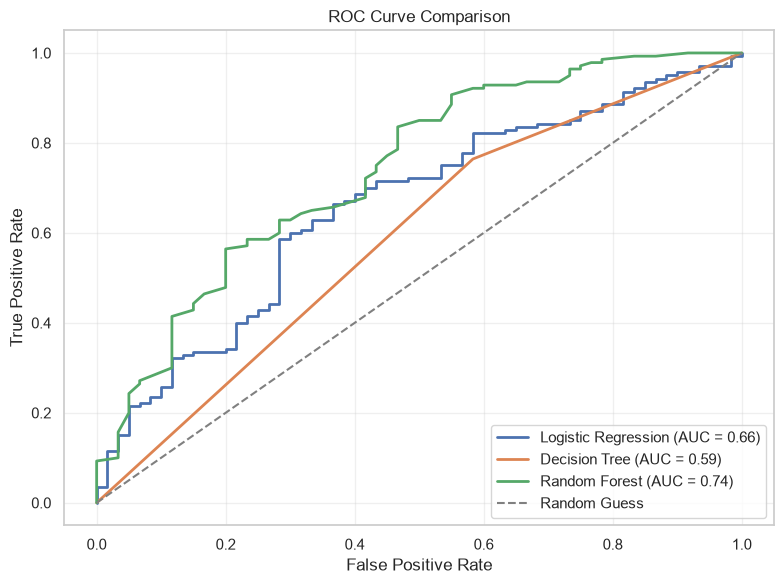

In [50]:
##calculate ROC data
# Logistic Regression
log_fpr, log_tpr, _ = roc_curve(y_test, y_prob)

# Decision Tree
tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_prob)

# Random Forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

## Plotting curves
plt.figure(figsize=(8, 6))

plt.plot(
    log_fpr,
    log_tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})",
    linewidth=2
)

plt.plot(
    tree_fpr,
    tree_tpr,
    label=f"Decision Tree (AUC = {tree_auc:.2f})",
    linewidth=2
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.2f})",
    linewidth=2
)

# Random guessing line
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

## Interpretation

The Random Forest ROC curve has the largest AUC (0.74), so it provides the best overall separation between `good` and `bad` risk records among the displayed baseline models.


# 13. Confusion Matrix Comparison

Each heatmap compares actual and predicted classes for one baseline model. Diagonal cells are correct predictions; off-diagonal cells are errors. Comparing the heatmaps makes the balance between correctly identifying `Bad` and `Good` risk records visible.


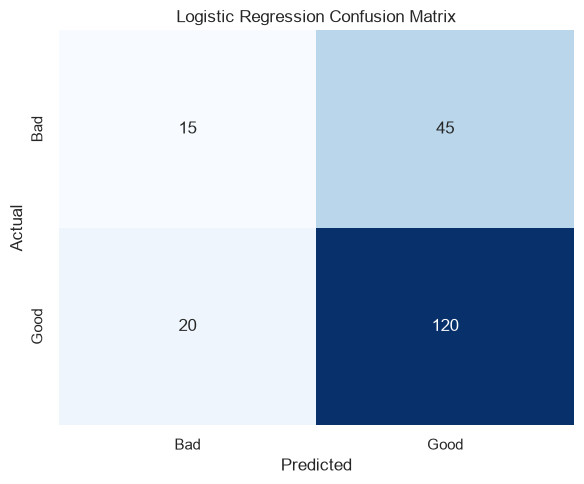

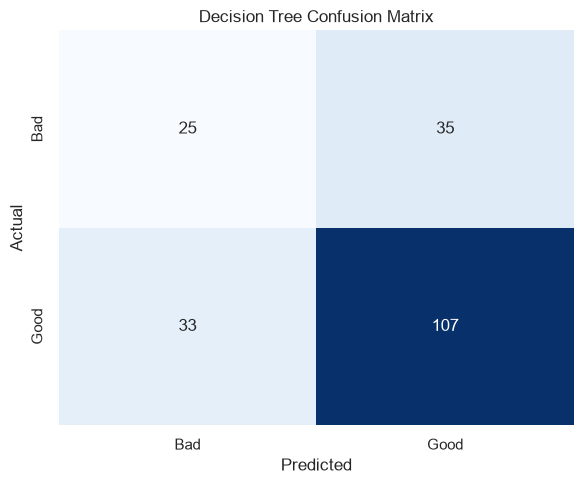

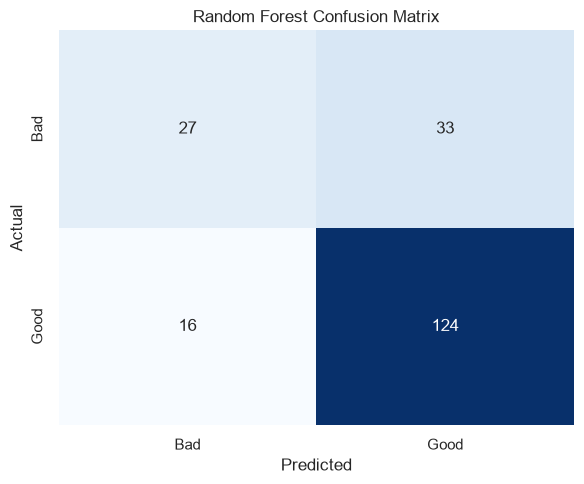

In [51]:
## Store matrices
log_cm = confusion_matrix(y_test, y_pred)
tree_cm = confusion_matrix(y_test, tree_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

## Reusable plotting fuction
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Bad", "Good"],
        yticklabels=["Bad", "Good"]
    )

    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

## Plot all three
plot_confusion_matrix(
    log_cm,
    "Logistic Regression Confusion Matrix"
)

plot_confusion_matrix(
    tree_cm,
    "Decision Tree Confusion Matrix"
)

plot_confusion_matrix(
    rf_cm,
    "Random Forest Confusion Matrix"
)



## Interpretation

The Random Forest heatmap has the largest number of correct predictions overall and correctly identifies more `Good` cases than the other models. As with the other models, identifying `Bad` risk remains harder because it is the smaller class.


# 14. Model Comparison

The table below compares the three baseline models using the unchanged test-set metrics. Random Forest is selected because it has the strongest accuracy, precision, recall, F1-score, and ROC-AUC among the baseline models.


In [52]:
## Final comparism table
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        tree_accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        tree_precision,
        rf_precision
    ],
    "Recall": [
        recall,
        tree_recall,
        rf_recall
    ],
    "F1-Score": [
        f1,
        tree_f1,
        rf_f1
    ],
    "ROC-AUC": [
        roc_auc,
        tree_auc,
        rf_auc
    ]
})

comparison = comparison.round(3)

comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.675,0.727,0.857,0.787,0.660
1,Decision Tree,0.660,0.754,0.764,0.759,0.590
2,Random Forest,0.755,0.790,0.886,0.835,0.741


## Interpretation

Random Forest leads the comparison table on every reported metric. Its stronger F1-score and ROC-AUC support selecting it over the Logistic Regression and Decision Tree baselines.


# 15. Final Model Selection

Random Forest is selected as the final model because it delivers the best performance across all reported baseline metrics on the independent test set. Although GridSearchCV found a promising tuned configuration during cross-validation, its held-out test accuracy and ROC-AUC were slightly lower than the baseline forest, so the baseline model is preferred for generalisation.

From a business perspective, the model can support consistent credit-risk screening by prioritising applicants likely to have `bad` risk for further review. It should support—not replace—human judgement, fairness review, and the institution's lending policy.


## Model Persistence

The selected baseline Random Forest and the fitted scaler are saved for reuse. This export does not alter model selection or evaluation results.


In [53]:
## Save the model
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_credit_model.pkl"
)

print("Random Forest model saved successfully!")

## Save the scalar
joblib.dump(
    scaler,
    "../models/standard_scaler.pkl"
)

print("Scaler saved successfully!")


Random Forest model saved successfully!
Scaler saved successfully!


# 16. Conclusion

This project evaluated Logistic Regression, Decision Tree, and Random Forest classifiers for credit scoring using the German Credit dataset. The workflow covered data-quality checks, missing-value handling, categorical encoding, feature scaling where appropriate, a stratified train/test split, and consistent test-set evaluation.

Random Forest was the best-performing baseline model, achieving 75.5% accuracy, an F1-score of 83.5%, and ROC-AUC of 74.1%. Credit amount, age, and duration were among its most influential features. The results show that an ensemble model can provide stronger credit-risk discrimination than the linear and single-tree alternatives tested here.


# 17. Future Improvements

- Evaluate on a larger, more recent, and more representative credit dataset.
- Compare additional algorithms, such as gradient boosting and calibrated classifiers.
- Use SHAP values to provide local and global explainability beyond impurity-based feature importance.
- Package the selected model in a monitored deployment workflow with data-quality and fairness checks.
- Create a Streamlit dashboard for transparent, user-friendly credit-risk exploration.
